# 03 · Busca: recall@1, recall@3 e limiar justificado

Comparamos três buscas sobre os casos `consta`: **embeddings** (cosseno, modelo `bge-m3` no Ollama), **BM25** (lexical) e **híbrida** (RRF dos dois).

Depois calibramos o **limiar de recusa** do agente: a similaridade máxima da pergunta com a base. Acima do limiar a pergunta *provavelmente* tem resposta; abaixo, o agente recusa antes de gerar.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
from rotalivre_ai import config, kb, metrics, montar, pipelines
from rotalivre_ai.runner import checar_ollama, rodar_todas
print(checar_ollama())

Ollama OK em http://localhost:11434 | LLM=qwen2.5:7b | embeddings=bge-m3


In [2]:
trechos, be, idx = montar()
casos = kb.carregar_casos()
linhas = []
for metodo in ["emb", "bm25", "hibrido"]:
    linhas.append({"busca": metodo, "recall@1": metrics.recall_at_k(idx, casos, 1, metodo), "recall@3": metrics.recall_at_k(idx, casos, 3, metodo)})
rec = pd.DataFrame(linhas).round(3)
rec.to_csv(config.RESULTS_DIR / "recall.csv", index=False)
rec

,busca,recall@1,recall@3
0,emb,0.846,0.923
1,bm25,0.769,0.885
2,hibrido,0.846,0.885


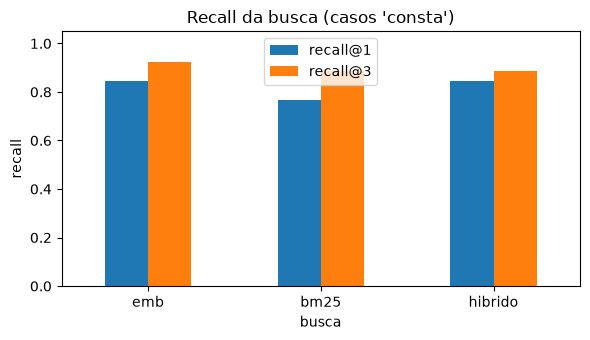

In [3]:
ax = rec.set_index("busca").plot.bar(rot=0, figsize=(6, 3.5), ylim=(0, 1.05))
ax.set_ylabel("recall"); ax.set_title("Recall da busca (casos 'consta')"); plt.tight_layout()
plt.savefig(config.RESULTS_DIR / "recall.png", dpi=130); plt.show()

In [4]:
# casos 'consta' em que o gabarito NÃO ficou no top-3 da busca vetorial (candidatos a erro real, nº 07)
falhas = []
for c in [c for c in casos if c["tipo"] == "consta"]:
    ids = [h.trecho.id for h in idx.buscar(c["pergunta"], k=3, metodo="emb")]
    if not set(ids) & set(c["trechos_gabarito"]):
        falhas.append({"caso": c["id"], "pergunta": c["pergunta"], "gabarito": c["trechos_gabarito"], "top3": ids})
pd.DataFrame(falhas) if falhas else "nenhuma falha de recall@3 na busca vetorial"


,caso,pergunta,gabarito,top3
0,C01,Qual a largura mínima da faixa livre da calçada segundo a NBR 9050?,[T11],"[T16, T13, T17]"
1,C02,Qual a altura livre mínima da faixa livre da calçada?,[T11],"[T16, T13, T17]"


## Limiar de recusa
Usamos o `cos_max` (maior cosseno entre a pergunta e todos os trechos). Escolhemos o limiar que **maximiza a estatística J de Youden** (taxa de verdadeiros 'consta' aceitos + taxa de verdadeiros 'não consta' recusados − 1).

In [5]:
cm = pd.DataFrame([{"id": c["id"], "tipo": c["tipo"], "cos_max": idx.cos_max(c["pergunta"])} for c in casos])
cands = np.round(np.linspace(cm.cos_max.min() - 0.01, cm.cos_max.max() + 0.01, 200), 4)
res = []
for L in cands:
    tpr = (cm[cm.tipo == "consta"].cos_max >= L).mean()      # 'consta' aceito
    tnr = (cm[cm.tipo == "nao_consta"].cos_max < L).mean()   # 'não consta' recusado
    res.append((L, tpr, tnr, tpr + tnr - 1))
res = pd.DataFrame(res, columns=["limiar", "TPR_consta", "TNR_nao_consta", "J"])
melhor = res[res.J == res.J.max()]
L = float(melhor.limiar.median())   # meio do intervalo ótimo
linha = res.iloc[(res.limiar - L).abs().argsort().iloc[0]]
print(f"limiar escolhido = {L:.3f} | aceita {linha.TPR_consta:.0%} dos 'consta' | recusa {linha.TNR_nao_consta:.0%} dos 'não consta' | J = {linha.J:.2f}")
(config.RESULTS_DIR / "limiar.json").write_text(json.dumps({"limiar": L, "J": float(linha.J), "TPR_consta": float(linha.TPR_consta), "TNR_nao_consta": float(linha.TNR_nao_consta), "metrica": "cos_max, Youden J", "embeddings": config.EMB_MODEL}, indent=2), encoding="utf-8")

limiar escolhido = 0.694 | aceita 73% dos 'consta' | recusa 100% dos 'não consta' | J = 0.73


169

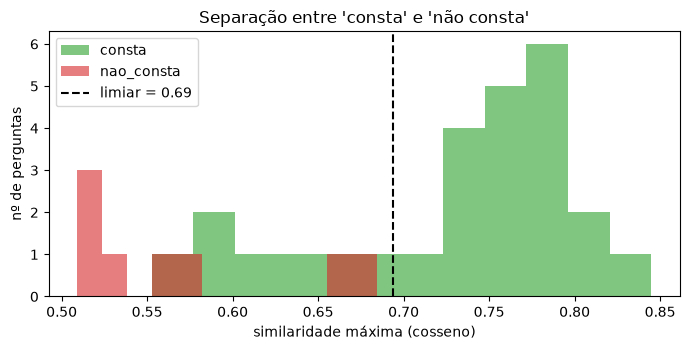

,id,tipo,cos_max
31,N06,nao_consta,0.509160
30,N05,nao_consta,0.515814
27,N02,nao_consta,0.522754
32,N07,nao_consta,0.524844
25,C26,consta,0.552675
26,N01,nao_consta,0.564088
33,N08,nao_consta,0.581760
23,C24,consta,0.593670
21,C22,consta,0.595066
20,C21,consta,0.623787


In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for tipo, cor in [("consta", "tab:green"), ("nao_consta", "tab:red")]:
    ax.hist(cm[cm.tipo == tipo].cos_max, bins=12, alpha=.6, label=tipo, color=cor)
ax.axvline(L, color="k", ls="--", label=f"limiar = {L:.2f}")
ax.set_xlabel("similaridade máxima (cosseno)"); ax.set_ylabel("nº de perguntas"); ax.legend(); ax.set_title("Separação entre 'consta' e 'não consta'")
plt.tight_layout(); plt.savefig(config.RESULTS_DIR / "limiar.png", dpi=130); plt.show()
cm.sort_values("cos_max")

### Justificativa do limiar (preencha com seus números ao rodar)
O limiar acima vem **dos dados**: é o ponto que melhor separa perguntas respondíveis das não respondíveis nos casos de teste. **Limitação:** com poucos casos o limiar tem incerteza; perguntas "não consta" muito próximas do vocabulário da base (como N03) podem ultrapassar o limiar, por isso o agente tem *segunda linha de defesa* (verificador + checagem determinística de números), mostrada no notebook 05.